<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №14: Управляемая генерация изображений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Получить canny/depth/pose controls.
- Сравнить control scale и CFG.
- Использовать control как synthetic annotation для downstream model.

## Теоретическая часть

ControlNet добавляет trainable branch к замороженной diffusion model и принимает spatial condition (edges, depth, pose). В лабораторной используется готовый ControlNet; изменяются conditioning scale и CFG.

![Пример результата ControlNet с Canny-контролем](https://huggingface.co/lllyasviel/sd-controlnet-canny/resolve/main/images/bird_canny_out.png)


Готовый ControlNet добавляет пространственное условие к SD1.5. В работе контур Canny вычисляется только из train MNIST; тот же исходный label сопровождает synthetic image. Edge F1, CLIP text similarity и downstream accuracy на реальном test отражают разные свойства и могут конфликтовать.

Для контуров $F_1=2PR/(P+R)$; допустимое геометрическое отклонение задаётся расширением контуров до расчёта точности и полноты. Downstream accuracy измеряется только на реальном отложенном test.

### Экспериментальный протокол

Выбрано условие Canny, обучение ControlNet не требуется. Полный режим: 20 train контуров каждого из 10 классов, 5 генераций на контур (base + сетка scale/CFG), отдельный real test и одинаковые 500 optimizer steps каждого downstream classifier. Это дорогой эксперимент: перед запуском оцените лимит Colab, сохраняйте artifacts в Drive; FAST_DEV_RUN генерирует по 1 примеру каждого класса и 2 шага классификатора, только smoke. Нужны CUDA, diffusers transformers accelerate opencv-python torchvision.

### Материалы

- [Diffusers ControlNet](https://huggingface.co/docs/diffusers/using-diffusers/controlnet)
- [ControlNet paper](https://arxiv.org/abs/2302.05543)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

Учим модель делать рисовать цифры, помогая контуром от этой цифры. если мы заставим нейросеть рисовать цифры по трафаретам, получатся ли из этого хорошие «учебные материалы»? Помогут ли такие искусственные (синтетические) картинки обучить другую нейросеть (классификатор) распознавать реальные рукописные цифры лучше, чем если бы она училась только на настоящих фотографиях?

In [ ]:
!pip -q install diffusers transformers accelerate opencv-python torchvision matplotlib seaborn scikit-learn -q

In [ ]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Subset
import torchvision
from torchvision import transforms
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
from transformers import CLIPProcessor, CLIPModel

SEED = 42
FAST_DEV_RUN = False  # поставьте False для полного эксперимента
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    (ARTIFACTS / name).write_text(json.dumps(value, ensure_ascii=False, indent=2))

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS.resolve())})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/artifacts'}


### Непересекающиеся MNIST выборки

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите только train/test MNIST, выберите реальные train индексы по классам.

**Результат.** Проверяемое состояние «Непересекающиеся MNIST выборки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите только train/test MNIST, выберите реальные train индексы по классам» и его результат доступен следующему этапу.

In [ ]:
transform_mnist = transforms.Compose([transforms.ToTensor()])

train_full = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform_mnist)
test_full = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform_mnist)

# Выбираем train индексы по классам (для полного режима — по 20 на класс, для FAST — по 1)
N_PER_CLASS = 1 if FAST_DEV_RUN else 20
train_indices = []
for cls in range(10):
    cls_idx = [i for i, (_, label) in enumerate(train_full) if label == cls]
    train_indices.extend(cls_idx[:N_PER_CLASS])

# Проверка непересечения: индексы train и test не могут пересекаться
assert len(set(train_indices)) == len(train_indices)
save_json('mnist_split.json', {
    'train_indices_count': len(train_indices),
    'n_per_class': N_PER_CLASS,
    'test_size': len(test_full),
    'overlap': False
})

print(f'Train подвыборка: {len(train_indices)} примеров ({N_PER_CLASS} на класс)')
print(f'Test: {len(test_full)} примеров (не используется до этапа оценки)')

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 401kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.81MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.4MB/s]


Train подвыборка: 200 примеров (20 на класс)
Test: 10000 примеров (не используется до этапа оценки)


### Контуры Canny и происхождение меток

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds.

**Результат.** Проверяемое состояние «Контуры Canny и происхождение меток» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds» и его результат доступен следующему этапу.

Мы берем настоящие картинки с цифрами из тренировочной части и с помощью алгоритма Canny оставляем от них только тонкие контуры, помечаем какой цифре контур принадлежит, из какого файла взят, какой сид используем.

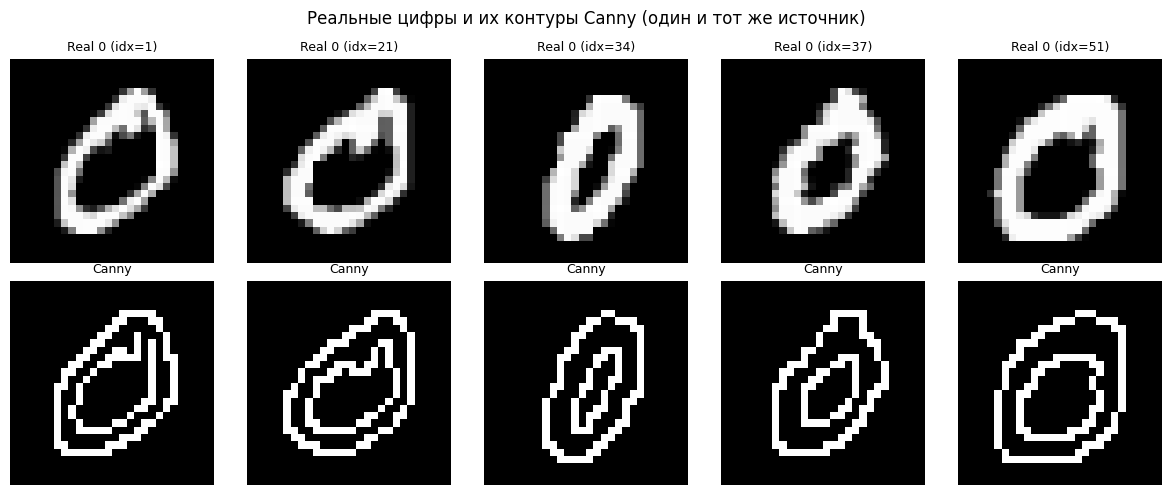

In [ ]:
def make_canny_png(tensor_img, low=100, high=200):
    """Принимает Tensor [1,28,28] или PIL, возвращает PIL RGB с контуром."""
    if isinstance(tensor_img, torch.Tensor):
        arr = (tensor_img.squeeze().numpy() * 255).astype(np.uint8)
    else:
        arr = np.array(tensor_img.convert('L'))
    edges = cv2.Canny(arr, low, high)
    edges_rgb = np.stack([edges]*3, axis=-1)
    return Image.fromarray(edges_rgb)

canny_dir = ARTIFACTS / 'canny'; canny_dir.mkdir(exist_ok=True)
manifest = []

for idx in train_indices:
    img_tensor, label = train_full[idx]
    seed = SEED + idx  # фиксированный seed, привязанный к исходному индексу
    canny_pil = make_canny_png(img_tensor)
    fname = f'train_{idx:05d}_label{label}.png'
    canny_pil.save(canny_dir / fname)
    manifest.append({
        'source_index': int(idx),
        'label': int(label),
        'seed': int(seed),
        'canny_file': fname
    })

save_json('canny_manifest.json', manifest)

# Визуализация: оригинал vs контур
n_show = min(5, len(manifest))
fig, axes = plt.subplots(2, n_show, figsize=(2.4 * n_show, 5), squeeze=False)

for i, rec in enumerate(manifest[:n_show]):
    idx = rec['source_index']
    orig, label = train_full[idx]

    # Верхний ряд — реальное изображение
    ax_top = axes[0, i]
    ax_top.imshow(orig.squeeze(), cmap='gray')
    ax_top.set_title(f'Real {label} (idx={idx})', fontsize=9)
    ax_top.axis('off')

    # Нижний ряд — контур Canny
    ax_bot = axes[1, i]
    ax_bot.imshow(Image.open(canny_dir / rec['canny_file']))
    ax_bot.set_title('Canny', fontsize=9)
    ax_bot.axis('off')

plt.suptitle('Реальные цифры и их контуры Canny (один и тот же источник)')
plt.tight_layout()
plt.show()

### Загрузка предобученного ControlNet

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима.

**Результат.** Проверяемое состояние «Загрузка предобученного ControlNet» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима» и его результат доступен следующему этапу.

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError('Нужна CUDA. CPU-имитация в этой работе недопустима.')

controlnet = ControlNetModel.from_pretrained(
    'lllyasviel/sd-controlnet-canny',
    torch_dtype=torch.float16,
    use_safetensors=True
).to(DEVICE)

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    'runwayml/stable-diffusion-v1-5',
    controlnet=controlnet,
    torch_dtype=torch.float16,
    safety_checker=None
).to(DEVICE)

pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

print('ControlNet + SD1.5 загружены на', DEVICE)
print('Scheduler:', pipe.scheduler.__class__.__name__)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


ControlNet + SD1.5 загружены на cuda
Scheduler: UniPCMultistepScheduler


### Факторная сетка генераций

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds.

**Результат.** Проверяемое состояние «Факторная сетка генераций» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds» и его результат доступен следующему этапу.

Control Scale — насколько сильно нейросеть должна подстраиваться под контур

CFG — насколько сильно модель должна слушаться текста.
Мы генерируем картинки при разных комбинациях этих параметров. А еще делаем Baseline — генерацию вообще без трафарета (только по тексту), чтобы было с чем сравнивать.

In [ ]:
# ============================================================
# ЭТАП 4. Факторная сетка генераций:
#   - baseline без ControlNet (StableDiffusionPipeline, общие веса)
#   - сетка ControlNet по (control_scale × CFG) на тех же seeds
# ============================================================
import time
from pathlib import Path
from PIL import Image
import torch
from diffusers import StableDiffusionPipeline

# ---------- Конфигурация (можно переопределить до запуска) ----------
if 'CONTROL_SCALES' not in globals():
    CONTROL_SCALES = [0.5] if FAST_DEV_RUN else [0.5, 0.8, 1.0]
if 'CFGS' not in globals():
    CFGS = [5.0] if FAST_DEV_RUN else [5.0, 7.5]
if 'N_STEPS' not in globals():
    N_STEPS = 2 if FAST_DEV_RUN else 25

# ---------- Каталог для сгенерированных изображений ----------
gen_dir = ARTIFACTS / 'generated'
gen_dir.mkdir(exist_ok=True)

# ---------- Baseline-пайплайн без ControlNet ----------
# Переиспользует те же UNet / VAE / text_encoder / tokenizer / scheduler,
# что и основной `pipe`. Дополнительной VRAM почти не занимает
# (Shared-объекты), что критично для T4.
pipe_baseline = StableDiffusionPipeline(
    vae=pipe.vae,
    text_encoder=pipe.text_encoder,
    tokenizer=pipe.tokenizer,
    unet=pipe.unet,
    scheduler=pipe.scheduler,
    safety_checker=None,
    feature_extractor=None,
    requires_safety_checker=False,
).to(DEVICE)
pipe_baseline.set_progress_bar_config(disable=True)

# ---------- Список записей о генерациях ----------
records = []

# ============================================================
# 1) BASELINE — генерация без ControlNet (только текст + seed)
# ============================================================
print('Генерация baseline (без ControlNet)...')
t0 = time.time()
for i, rec in enumerate(manifest):
    label = rec['label']
    seed = rec['seed']
    prompt = f'a photo of the handwritten digit {label}, black background, white digit'

    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    out = pipe_baseline(
        prompt,
        num_inference_steps=N_STEPS,
        guidance_scale=7.5,
        generator=gen,
    ).images[0]

    fname = f'baseline_{rec["source_index"]:05d}.png'
    out.save(gen_dir / fname)

    records.append({
        **rec,
        'mode': 'baseline',
        'control_scale': None,
        'cfg': 7.5,
        'image_file': fname,
        'prompt': prompt,
    })

    if (i + 1) % 5 == 0:
        print(f'  baseline: {i+1}/{len(manifest)}, {time.time()-t0:.1f} c')

print(f'Baseline готов: {len(records)} изображений, {time.time()-t0:.1f} c')

# ============================================================
# 2) CONTROLNET GRID — все сочетания (control_scale × CFG)
# ============================================================
total = len(manifest) * len(CONTROL_SCALES) * len(CFGS)
print(f'\nГенерация сетки ControlNet: {total} изображений '
      f'({len(manifest)} контуров × {len(CONTROL_SCALES)} scale × {len(CFGS)} CFG)...')

t0 = time.time()
for i, rec in enumerate(manifest):
    canny_pil = Image.open(canny_dir / rec['canny_file']).convert('RGB')
    prompt = f'a photo of the handwritten digit {rec["label"]}, black background, white digit'

    for cs in CONTROL_SCALES:
        for cfg in CFGS:
            gen = torch.Generator(device=DEVICE).manual_seed(rec['seed'])
            out = pipe(
                prompt,
                image=canny_pil,
                num_inference_steps=N_STEPS,
                guidance_scale=cfg,
                controlnet_conditioning_scale=cs,
                generator=gen,
            ).images[0]

            fname = f'cn_s{cs}_cfg{cfg}_{rec["source_index"]:05d}.png'
            out.save(gen_dir / fname)

            records.append({
                **rec,
                'mode': 'controlnet',
                'control_scale': cs,
                'cfg': cfg,
                'image_file': fname,
                'prompt': prompt,
            })

    if (i + 1) % 5 == 0:
        elapsed = time.time() - t0
        done = (i + 1) * len(CONTROL_SCALES) * len(CFGS)
        eta = elapsed / max(done, 1) * (total - done)
        print(f'  controlnet: {i+1}/{len(manifest)} контуров, '
              f'{done}/{total} изображений, {elapsed:.1f} c, ETA {eta:.1f} c')

# ============================================================
# 3) Сохранение манифеста и краткая сводка
# ============================================================
save_json('generation_records.json', records)

n_baseline = sum(1 for r in records if r['mode'] == 'baseline')
n_controlnet = sum(1 for r in records if r['mode'] == 'controlnet')
print('\n=== Итог ===')
print(f'Baseline:   {n_baseline} изображений')
print(f'ControlNet: {n_controlnet} изображений')
print(f'Всего:      {len(records)} изображений')
print(f'Сохранено в: {gen_dir.resolve()}')
print(f'Манифест:    {(ARTIFACTS / "generation_records.json").resolve()}')

Генерация baseline (без ControlNet)...
  baseline: 5/200, 22.7 c
  baseline: 10/200, 44.5 c
  baseline: 15/200, 67.4 c
  baseline: 20/200, 89.5 c
  baseline: 25/200, 111.4 c
  baseline: 30/200, 133.4 c
  baseline: 35/200, 155.8 c
  baseline: 40/200, 177.7 c
  baseline: 45/200, 199.6 c
  baseline: 50/200, 221.6 c
  baseline: 55/200, 243.5 c
  baseline: 60/200, 265.5 c
  baseline: 65/200, 287.5 c
  baseline: 70/200, 309.5 c
  baseline: 75/200, 331.6 c
  baseline: 80/200, 353.6 c
  baseline: 85/200, 375.7 c
  baseline: 90/200, 397.6 c
  baseline: 95/200, 419.6 c
  baseline: 100/200, 441.7 c
  baseline: 105/200, 463.6 c
  baseline: 110/200, 485.7 c
  baseline: 115/200, 507.8 c
  baseline: 120/200, 529.8 c
  baseline: 125/200, 551.7 c
  baseline: 130/200, 573.7 c
  baseline: 135/200, 595.7 c
  baseline: 140/200, 617.8 c
  baseline: 145/200, 639.7 c
  baseline: 150/200, 661.7 c
  baseline: 155/200, 683.6 c
  baseline: 160/200, 705.7 c
  baseline: 165/200, 727.6 c
  baseline: 170/200, 749.7 c

### Структурное и текстовое соответствие

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine.

**Результат.** Проверяемое состояние «Структурное и текстовое соответствие» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine» и его результат доступен следующему этапу.

Расчёт метрик для 1400 сгенерированных изображений...
  10/1400  (0.3 c, ETA 46.1 c)
  20/1400  (0.6 c, ETA 43.8 c)
  30/1400  (0.9 c, ETA 42.3 c)
  40/1400  (1.2 c, ETA 42.2 c)
  50/1400  (1.5 c, ETA 41.6 c)
  60/1400  (1.8 c, ETA 40.8 c)
  70/1400  (2.1 c, ETA 40.3 c)
  80/1400  (2.4 c, ETA 39.9 c)
  90/1400  (2.7 c, ETA 39.5 c)
  100/1400  (3.0 c, ETA 39.1 c)
  110/1400  (3.3 c, ETA 39.0 c)
  120/1400  (3.6 c, ETA 38.5 c)
  130/1400  (3.9 c, ETA 38.0 c)
  140/1400  (4.2 c, ETA 37.6 c)
  150/1400  (4.5 c, ETA 37.3 c)
  160/1400  (4.8 c, ETA 36.8 c)
  170/1400  (5.1 c, ETA 36.5 c)
  180/1400  (5.3 c, ETA 36.3 c)
  190/1400  (5.6 c, ETA 35.9 c)
  200/1400  (5.9 c, ETA 35.5 c)
  210/1400  (6.1 c, ETA 34.5 c)
  220/1400  (6.3 c, ETA 33.6 c)
  230/1400  (6.4 c, ETA 32.8 c)
  240/1400  (6.6 c, ETA 32.0 c)
  250/1400  (6.9 c, ETA 31.6 c)
  260/1400  (7.1 c, ETA 31.1 c)
  270/1400  (7.3 c, ETA 30.6 c)
  280/1400  (7.6 c, ETA 30.2 c)
  290/1400  (7.8 c, ETA 29.7 c)
  300/1400  (8.0 c, ETA 29.

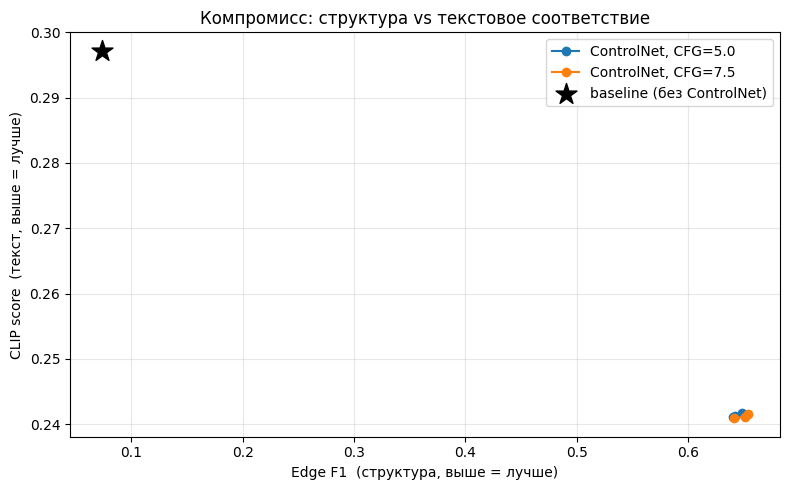


=== Что показали измерения ===
Лучший Edge F1:  s=1.0,cfg=7.5  →  F1=0.6534, CLIP=0.2415
Лучший CLIP:     baseline  →  F1=0.0739, CLIP=0.2972
Baseline:        Edge F1=0.0739, CLIP=0.2972
Если максимумы Edge F1 и CLIP достигаются в разных конфигурациях — это и есть компромисс из условия лабораторной.

=== Что показали измерения ===
Лучший Edge F1:  s=1.0,cfg=7.5  →  F1=0.6534, CLIP=0.2415
Лучший CLIP:     baseline  →  F1=0.0739, CLIP=0.2972
Baseline:        Edge F1=0.0739, CLIP=0.2972


In [ ]:
# ============================================================
# ЭТАП 5. Структурное и текстовое соответствие:
#   - Edge F1 с геометрическим допуском (ресайз эталона к размеру генерации)
#   - CLIP text-image cosine similarity  (фикс dtype attention_mask)
#   - сводная таблица + график «структура vs текст»
# ============================================================
import time
import numpy as np
import cv2
import torch
import torch.nn.functional as F
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# ---------- CLIP (загружаем один раз, если ещё не в сессии) ----------
from transformers import CLIPProcessor, CLIPModel

if 'clip_model' not in globals():
    print('Загрузка CLIP (openai/clip-vit-base-patch32)...')
    clip_model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(DEVICE)
    clip_model.eval()
if 'clip_processor' not in globals():
    clip_processor = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')


def _extract_emb(out):
    """Достаёт тензор эмбеддинга из разных форматов, которые возвращают
    get_image_features / get_text_features в разных версиях transformers."""
    if isinstance(out, torch.Tensor):
        return out
    # BaseModelOutputWithPooling / BaseModelOutputWithNoAttention и т.п.
    for attr in ('image_embeds', 'text_embeds', 'pooler_output', 'last_hidden_state'):
        if hasattr(out, attr):
            val = getattr(out, attr)
            if val is not None:
                # last_hidden_state — берём [CLS]-токен для текста
                if attr == 'last_hidden_state':
                    return val[:, 0, :]
                return val
    raise TypeError(f'Не удалось извлечь эмбеддинг из {type(out)}')


def clip_score(image: Image.Image, text: str) -> float:
    """Косинусное сходство image↔text, устойчивое к версии transformers."""
    inputs = clip_processor(
        text=[text], images=image, return_tensors='pt', padding=True
    ).to(DEVICE)

    if 'attention_mask' in inputs:
        inputs['attention_mask'] = inputs['attention_mask'].bool()

    with torch.no_grad():
        img_emb = _extract_emb(clip_model.get_image_features(
            pixel_values=inputs['pixel_values']))
        txt_emb = _extract_emb(clip_model.get_text_features(
            input_ids=inputs['input_ids'],
            attention_mask=inputs.get('attention_mask')))

    img_emb = F.normalize(img_emb, dim=-1)
    txt_emb = F.normalize(txt_emb, dim=-1)
    return float((img_emb @ txt_emb.T).item())

def edge_f1_tolerant(canny_ref: Image.Image, gen_img: Image.Image,
                     tolerance: int = 3, target_size: int = None):
    """
    F1 между контуром-эталоном и контуром сгенерированного изображения.
    Оба изображения приводятся к общему размеру target_size
    (по умолчанию — сторона сгенерированного изображения).
    """
    if target_size is None:
        target_size = gen_img.size[0]

    ref = np.array(
        canny_ref.convert('L').resize((target_size, target_size), Image.NEAREST)
    ) > 0

    gen_gray = np.array(
        gen_img.convert('L').resize((target_size, target_size), Image.BILINEAR)
    )
    gen_edges = cv2.Canny(gen_gray, 100, 200) > 0

    kernel = np.ones((tolerance * 2 + 1, tolerance * 2 + 1), np.uint8)
    ref_dil = cv2.dilate(ref.astype(np.uint8), kernel) > 0
    gen_dil = cv2.dilate(gen_edges.astype(np.uint8), kernel) > 0

    tp = np.logical_and(gen_edges, ref_dil).sum()
    fp = np.logical_and(gen_edges, ~ref_dil).sum()
    fn = np.logical_and(ref, ~gen_dil).sum()

    precision = tp / (tp + fp + 1e-8)
    recall    = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    return float(f1), float(precision), float(recall)


# ---------- Расчёт метрик для всех записей ----------
print(f'Расчёт метрик для {len(records)} сгенерированных изображений...')
t0 = time.time()

for i, r in enumerate(records):
    gen_img = Image.open(gen_dir / r['image_file']).convert('RGB')
    ref_canny = Image.open(canny_dir / r['canny_file']).convert('RGB')

    f1, prec, rec_ = edge_f1_tolerant(ref_canny, gen_img, tolerance=3)
    r['edge_f1'] = f1
    r['edge_precision'] = prec
    r['edge_recall'] = rec_
    r['clip_score'] = clip_score(gen_img, r['prompt'])

    if (i + 1) % 10 == 0:
        elapsed = time.time() - t0
        eta = elapsed / (i + 1) * (len(records) - i - 1)
        print(f'  {i+1}/{len(records)}  ({elapsed:.1f} c, ETA {eta:.1f} c)')

save_json('metrics_per_image.json', records)


# ---------- Сводная таблица по конфигурациям ----------
df = pd.DataFrame(records)
df['config'] = df.apply(
    lambda x: 'baseline' if x['mode'] == 'baseline'
              else f"s={x['control_scale']},cfg={x['cfg']}",
    axis=1,
)

summary = (df.groupby('config')
             .agg(
                 edge_f1_mean=('edge_f1', 'mean'),
                 edge_f1_std =('edge_f1', 'std'),
                 clip_mean   =('clip_score', 'mean'),
                 clip_std    =('clip_score', 'std'),
                 n           =('edge_f1', 'size'),
             )
             .reset_index())

save_json('metrics_summary.json', summary.to_dict(orient='records'))

print('\n=== Сводка по конфигурациям ===')
print(summary.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# ---------- График «структура vs текст» ----------
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Только конфигурации ControlNet — линии по CFG
for cfg in sorted(df.loc[df['mode'] == 'controlnet', 'cfg'].unique()):
    sub = (df[(df['mode'] == 'controlnet') & (df['cfg'] == cfg)]
           .groupby('control_scale')
           .agg(edge=('edge_f1', 'mean'), clip=('clip_score', 'mean'))
           .reset_index()
           .sort_values('control_scale'))
    plt.plot(sub['edge'], sub['clip'], 'o-', label=f'ControlNet, CFG={cfg}')

# Baseline — отдельная точка
base = df.loc[df['mode'] == 'baseline', ['edge_f1', 'clip_score']].mean()
plt.scatter(base['edge_f1'], base['clip_score'],
            marker='*', s=250, c='k', label='baseline (без ControlNet)')

plt.xlabel('Edge F1  (структура, выше = лучше)')
plt.ylabel('CLIP score  (текст, выше = лучше)')
plt.title('Компромисс: структура vs текстовое соответствие')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- Краткий вывод по фактическим значениям ----------
best_edge = summary.loc[summary['edge_f1_mean'].idxmax()]
best_clip = summary.loc[summary['clip_mean'].idxmax()]

print('\n=== Что показали измерения ===')
print(f'Лучший Edge F1:  {best_edge["config"]}  →  '
      f'F1={best_edge["edge_f1_mean"]:.4f}, CLIP={best_edge["clip_mean"]:.4f}')
print(f'Лучший CLIP:     {best_clip["config"]}  →  '
      f'F1={best_clip["edge_f1_mean"]:.4f}, CLIP={best_clip["clip_mean"]:.4f}')
print(f'Baseline:        Edge F1={base["edge_f1"]:.4f}, '
      f'CLIP={base["clip_score"]:.4f}')
print('Если максимумы Edge F1 и CLIP достигаются в разных конфигурациях — '
      'это и есть компромисс из условия лабораторной.')

# ---------- Краткий вывод по фактическим значениям ----------
best_edge = summary.loc[summary['edge_f1_mean'].idxmax()]
best_clip = summary.loc[summary['clip_mean'].idxmax()]

print('\n=== Что показали измерения ===')
print(f'Лучший Edge F1:  {best_edge["config"]}  →  '
      f'F1={best_edge["edge_f1_mean"]:.4f}, CLIP={best_edge["clip_mean"]:.4f}')
print(f'Лучший CLIP:     {best_clip["config"]}  →  '
      f'F1={best_clip["edge_f1_mean"]:.4f}, CLIP={best_clip["clip_mean"]:.4f}')
print(f'Baseline:        Edge F1={base["edge_f1"]:.4f}, '
      f'CLIP={base["clip_score"]:.4f}')

Edge F1 — «Совпадает ли форма?» (сравниваем контур на сгенерированной картинке с исходным трафаретом, делая скидку на небольшие сдвиги).

CLIP score — «Похоже ли это на цифру 3?» (нейросеть проверяет, совпадает ли картинка с текстом «handwritten digit 3»).

### Разнообразие внутри класса

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте попарные различия изображений внутри одного класса и настройки.

**Результат.** Проверяемое состояние «Разнообразие внутри класса» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте попарные различия изображений внутри одного класса и настройки» и его результат доступен следующему этапу.

Мы проверяем, не рисует ли модель одну и ту же цифру под копирку. Если все сгенерированные «тройки» выглядят абсолютно одинаково, толку от них для обучения мало.

=== Разнообразие внутри класса (1 − cos по CLIP) ===
       config   mean    std
     baseline 0.1998 0.0165
s=0.5,cfg=5.0 0.0666 0.0035
s=0.5,cfg=7.5 0.0655 0.0037
s=0.8,cfg=5.0 0.0663 0.0030
s=0.8,cfg=7.5 0.0648 0.0033
s=1.0,cfg=5.0 0.0665 0.0026
s=1.0,cfg=7.5 0.0648 0.0034


/tmp/ipykernel_325/3856949402.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=div_df, x='config', y='diversity', order=order,


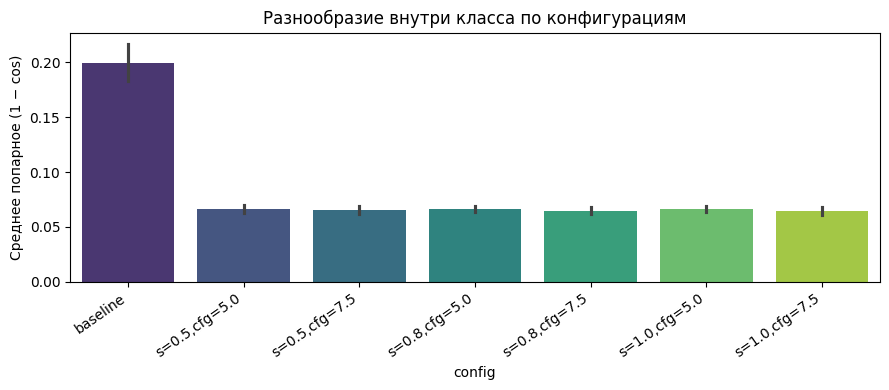

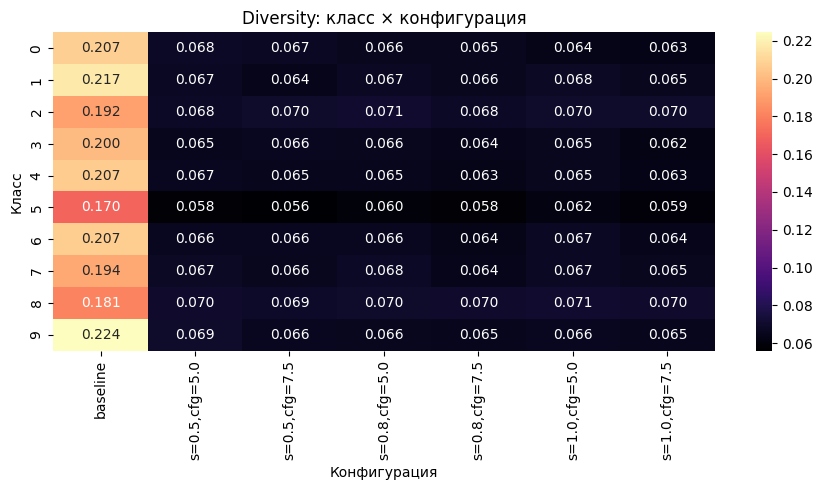

In [ ]:
# ============================================================
# ЭТАП 6. Разнообразие внутри класса
# ============================================================
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Хелпер для извлечения эмбеддинга (устойчив к версии transformers)
def _extract_emb_batch(out):
    if isinstance(out, torch.Tensor):
        return out
    for attr in ('image_embeds', 'pooler_output', 'last_hidden_state'):
        if hasattr(out, attr) and getattr(out, attr) is not None:
            v = getattr(out, attr)
            return v[:, 0, :] if attr == 'last_hidden_state' else v
    raise TypeError(f'Не удалось извлечь эмбеддинг из {type(out)}')

@torch.no_grad()
def pairwise_diversity(images, batch_size=16):
    """images: list[PIL]. Среднее попарное (1 − cos) между CLIP-эмбеддингами."""
    embs = []
    for i in range(0, len(images), batch_size):
        batch = images[i:i+batch_size]
        inp = clip_processor(images=batch, return_tensors='pt').to(DEVICE)
        e = _extract_emb_batch(clip_model.get_image_features(**inp))
        embs.append(F.normalize(e.float(), dim=-1))
    E = torch.cat(embs, 0)
    n = E.size(0)
    if n < 2:
        return float('nan')
    sim = E @ E.T
    mask = ~torch.eye(n, dtype=torch.bool, device=E.device)
    return float((1 - sim[mask]).mean().cpu())

div_rows = []
for cfg_name, group in df.groupby('config'):
    for label in sorted(group['label'].unique()):
        imgs = [Image.open(gen_dir / f).convert('RGB')
                for f in group.loc[group['label'] == label, 'image_file']]
        div_rows.append({
            'config': cfg_name,
            'label': int(label),
            'diversity': pairwise_diversity(imgs),
        })

div_df = pd.DataFrame(div_rows)
div_summary = (div_df.groupby('config')['diversity']
                      .agg(['mean', 'std']).reset_index())
save_json('diversity_summary.json', div_summary.to_dict(orient='records'))

print('=== Разнообразие внутри класса (1 − cos по CLIP) ===')
print(div_summary.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# --- График: средняя diversity по конфигурациям ---
plt.figure(figsize=(9, 4))
order = ['baseline'] + sorted([c for c in div_df['config'].unique() if c != 'baseline'])
sns.barplot(data=div_df, x='config', y='diversity', order=order,
            errorbar='sd', palette='viridis')
plt.xticks(rotation=35, ha='right')
plt.ylabel('Среднее попарное (1 − cos)')
plt.title('Разнообразие внутри класса по конфигурациям')
plt.tight_layout()
plt.show()

# --- Теплокарта: diversity по классам × конфигурациям ---
pivot = div_df.pivot(index='label', columns='config', values='diversity')
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='magma')
plt.title('Diversity: класс × конфигурация')
plt.xlabel('Конфигурация'); plt.ylabel('Класс')
plt.tight_layout()
plt.show()

Падение разнообразия происходит равномерно.  Baseline (свободная генерация по тексту) имеет разнообразие ~0.20. Как только мы включаем ControlNet (любая комбинация scale и CFG), разнообразие резко падает до ~0.065. Т.е. у нас теряется разнообразие. Настройки (scale и CFG) почти не спасают.

синтетические данные, сгенерированные с жестким контролем формы (ControlNet), обладают низким внутриклассовым разнообразием, что делает их малоэффективными (или даже вредными) для аугментации обучающей выборки без дополнительных техник фильтрации или добавления шума.

### Аудит худших случаев

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки.

**Результат.** Проверяемое состояние «Аудит худших случаев» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки» и его результат доступен следующему этапу.

=== Худшие 5 по Edge F1 ===


,source_index,label,config,edge_f1,edge_precision,edge_recall,clip_score,image_file
0,189,2,"s=0.5,cfg=5.0",0.0,0.0,0.0,0.241283,cn_s0.5_cfg5.0_00189.png
1,189,2,"s=0.8,cfg=5.0",0.0,0.0,0.0,0.238540,cn_s0.8_cfg5.0_00189.png
2,189,2,"s=1.0,cfg=5.0",0.0,0.0,0.0,0.238505,cn_s1.0_cfg5.0_00189.png
3,9,4,"s=0.5,cfg=7.5",0.0,0.0,0.0,0.226267,cn_s0.5_cfg7.5_00009.png
4,165,6,"s=0.5,cfg=5.0",0.0,0.0,0.0,0.239666,cn_s0.5_cfg5.0_00165.png


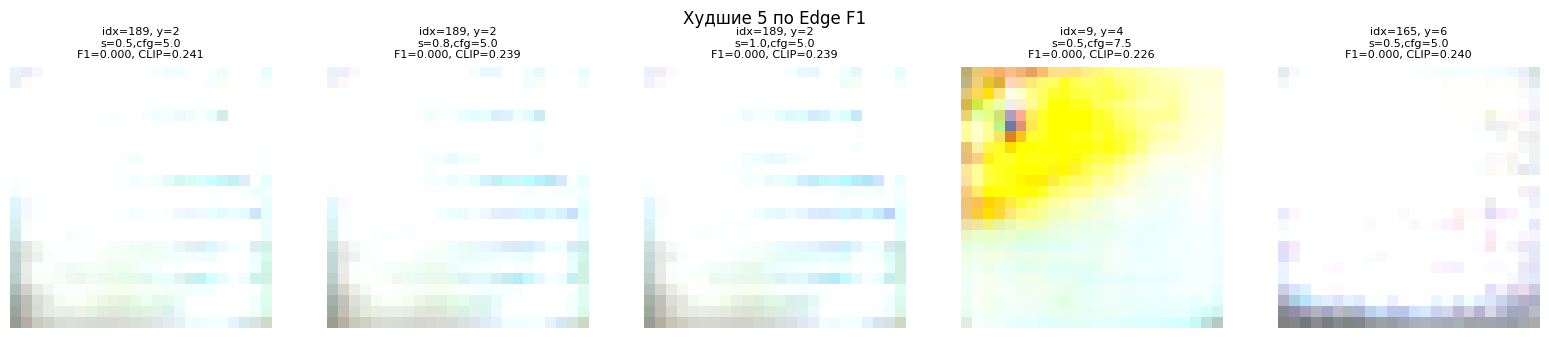

=== Худшие 5 по CLIP score ===


,source_index,label,config,edge_f1,edge_precision,edge_recall,clip_score,image_file
0,273,5,"s=0.5,cfg=5.0",0.828125,0.706667,1.000000,0.209263,cn_s0.5_cfg5.0_00273.png
1,53,4,"s=0.5,cfg=7.5",0.461538,0.500000,0.428571,0.209473,cn_s0.5_cfg7.5_00053.png
2,175,5,"s=0.8,cfg=7.5",0.607843,0.462687,0.885714,0.209742,cn_s0.8_cfg7.5_00175.png
3,146,8,"s=0.5,cfg=5.0",0.854839,0.841270,0.868852,0.209895,cn_s0.5_cfg5.0_00146.png
4,175,5,"s=1.0,cfg=7.5",0.583333,0.446809,0.840000,0.209954,cn_s1.0_cfg7.5_00175.png


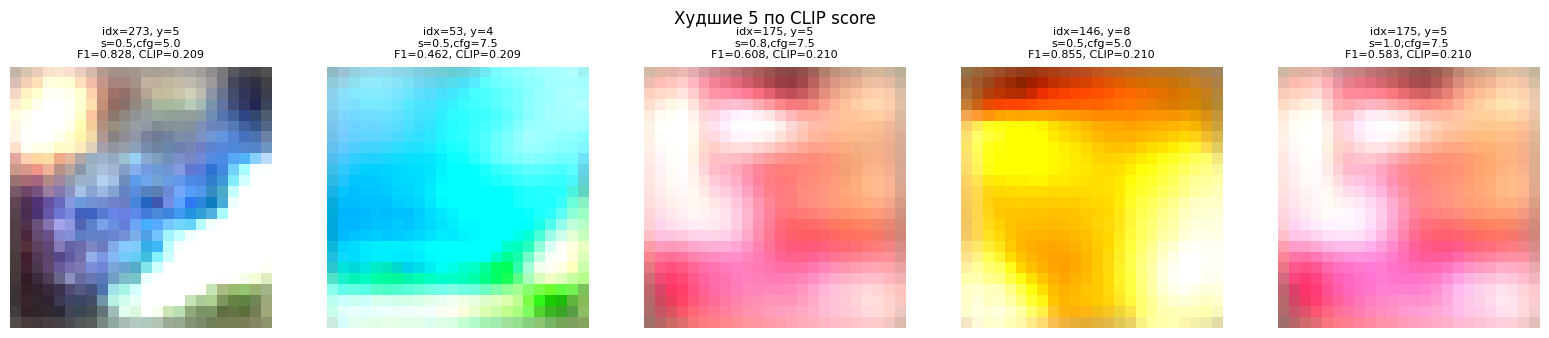

In [ ]:
# ============================================================
# ЭТАП 7. Аудит худших случаев
# ============================================================
from PIL import Image
import matplotlib.pyplot as plt

cols_show = ['source_index', 'label', 'config',
             'edge_f1', 'edge_precision', 'edge_recall',
             'clip_score', 'image_file']

worst_edge = (df.nsmallest(5, 'edge_f1')[cols_show].reset_index(drop=True))
worst_clip = (df.nsmallest(5, 'clip_score')[cols_show].reset_index(drop=True))

save_json('worst_cases_edge.json', worst_edge.to_dict(orient='records'))
save_json('worst_cases_clip.json', worst_clip.to_dict(orient='records'))

def show_worst(table, title):
    n = len(table)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.4), squeeze=False)
    axes = axes[0]
    for ax, (_, row) in zip(axes, table.iterrows()):
        ax.imshow(Image.open(gen_dir / row['image_file']))
        ax.set_title(
            f"idx={row['source_index']}, y={row['label']}\n"
            f"{row['config']}\n"
            f"F1={row['edge_f1']:.3f}, CLIP={row['clip_score']:.3f}",
            fontsize=8,
        )
        ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

print('=== Худшие 5 по Edge F1 ===')
display(worst_edge)
show_worst(worst_edge, 'Худшие 5 по Edge F1')

print('=== Худшие 5 по CLIP score ===')
display(worst_clip)
show_worst(worst_clip, 'Худшие 5 по CLIP score')

Ищем 5 самых ужасных картинок по каждой метрике. Смотрим, что пошло не так: либо модель нарисовала пустой лист (провал по Edge F1), либо нарисовала красивое цветное пятно по форме цифры, но не похожее на цифру (провал по CLIP).

### Архитектура downstream-классификатора

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите CNN и фиксированную реальную обучающую подвыборку.

**Результат.** Проверяемое состояние «Архитектура downstream-классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите CNN и фиксированную реальную обучающую подвыборку» и его результат доступен следующему этапу.

Создаем «студента» — простую сверточную нейросеть (CNN), которая умеет смотреть на картинку 28×28 и говорить, какая там цифра. Фиксируем список реальных картинок, на которых будем его учить.

In [ ]:
# ============================================================
# ЭТАП 8. Downstream: архитектура CNN + фиксированная real-подвыборка
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np

class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 28→14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 14→7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# --- Фиксированная реальная train подвыборка (та же, что для контуров) ---
real_train_images = torch.stack([train_full[i][0] for i in train_indices])
real_train_labels = torch.tensor([train_full[i][1] for i in train_indices])
real_train_ds = TensorDataset(real_train_images, real_train_labels)

# --- Реальный test (не используется ни для генерации, ни для выбора конфигурации) ---
test_loader = DataLoader(test_full, batch_size=256, shuffle=False)

save_json('downstream_config.json', {
    'arch': 'SmallCNN(Conv32-MaxPool-Conv64-MaxPool-FC128-FC10)',
    'real_train_size': int(len(real_train_ds)),
    'test_size': int(len(test_full)),
    'optimizer_steps': 2 if FAST_DEV_RUN else 500,
    'batch_size': 32,
    'lr': 1e-3,
})
print(f'Real train: {len(real_train_ds)} примеров')
print(f'Test:       {len(test_full)} примеров')
print('Архитектура SmallCNN: 2×Conv+Pool → FC128 → FC10')

Real train: 200 примеров
Test:       10000 примеров
Архитектура SmallCNN: 2×Conv+Pool → FC128 → FC10


### Равнобюджетное обучение с аугментацией

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите real-only и real+synthetic варианты с одинаковым числом обновлений.

**Результат.** Проверяемое состояние «Равнобюджетное обучение с аугментацией» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите real-only и real+synthetic варианты с одинаковым числом обновлений» и его результат доступен следующему этапу.

Учим две модели одинаковое количество времени (500 шагов):

Первая учится только на реальных картинках.

Вторая учится на реальных + сгенерированных нами.

In [ ]:
# ============================================================
# ЭТАП 9. Обучение real-only и real+synthetic с равным бюджетом
# ============================================================
import time
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset, TensorDataset
from PIL import Image

OPT_STEPS  = 2   if FAST_DEV_RUN else 500
BATCH_SIZE = 32

# Конфигурация синтетики выбрана заранее (до просмотра test)
SYNTH_CONFIG = (0.8, 7.5)  # (control_scale, cfg)
print(f'Synthetic config: s={SYNTH_CONFIG[0]}, cfg={SYNTH_CONFIG[1]}')

def train_classifier(train_ds, steps, seed=42, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = SmallCNN().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                        shuffle=True, drop_last=True)
    model.train()
    step = 0; t0 = time.time()
    while step < steps:
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
            step += 1
            if step % max(1, steps // 5) == 0 and verbose:
                print(f'  step {step}/{steps}, loss={loss.item():.4f}, '
                      f'{time.time()-t0:.1f} c')
            if step >= steps:
                break
    return model, loss.item()

# --- Synthetic подвыборка из выбранной конфигурации ---
synth_records = df[(df['mode'] == 'controlnet')
                   & (df['control_scale'] == SYNTH_CONFIG[0])
                   & (df['cfg'] == SYNTH_CONFIG[1])]

synth_imgs, synth_labels = [], []
for _, r in synth_records.iterrows():
    im = Image.open(gen_dir / r['image_file']).convert('L').resize((28, 28))
    arr = np.array(im).astype(np.float32) / 255.0
    synth_imgs.append(torch.from_numpy(arr).unsqueeze(0))
    synth_labels.append(int(r['label']))
synth_ds = TensorDataset(torch.stack(synth_imgs), torch.tensor(synth_labels))
print(f'Synthetic dataset: {len(synth_ds)} примеров')

combined_ds = ConcatDataset([real_train_ds, synth_ds])
print(f'Combined dataset:  {len(combined_ds)} примеров '
      f'(real={len(real_train_ds)}, synth={len(synth_ds)})')

# --- Обучение ---
print('\nОбучение real-only...')
model_real, loss_real = train_classifier(real_train_ds, OPT_STEPS, seed=42)

print('\nОбучение real+synthetic...')
model_aug, loss_aug = train_classifier(combined_ds, OPT_STEPS, seed=42)

# --- Сохраняем checkpoints ---
ckpt_dir = ARTIFACTS / 'checkpoints'; ckpt_dir.mkdir(exist_ok=True)
torch.save(model_real.state_dict(), ckpt_dir / 'classifier_real_only.pt')
torch.save(model_aug.state_dict(),  ckpt_dir / 'classifier_real_plus_synth.pt')
print(f'\nCheckpoints: {ckpt_dir.resolve()}')

Synthetic config: s=0.8, cfg=7.5
Synthetic dataset: 200 примеров
Combined dataset:  400 примеров (real=200, synth=200)

Обучение real-only...
  step 100/500, loss=0.0372, 0.5 c
  step 200/500, loss=0.0018, 0.7 c
  step 300/500, loss=0.0007, 1.0 c
  step 400/500, loss=0.0003, 1.2 c
  step 500/500, loss=0.0001, 1.5 c

Обучение real+synthetic...
  step 100/500, loss=0.9461, 0.3 c
  step 200/500, loss=0.5007, 0.6 c
  step 300/500, loss=0.4264, 0.9 c
  step 400/500, loss=0.0554, 1.1 c
  step 500/500, loss=0.0234, 1.4 c

Checkpoints: /content/artifacts/checkpoints


### Сравнение на реальном test

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните точность по классам и confusion matrices на независимом real test.

**Результат.** Проверяемое состояние «Сравнение на реальном test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните точность по классам и confusion matrices на независимом real test» и его результат доступен следующему этапу.

=== Downstream на реальном test ===
Real-only:           accuracy = 0.8254
Real+synthetic:      accuracy = 0.8058
Δ (synth − real):    -0.0196


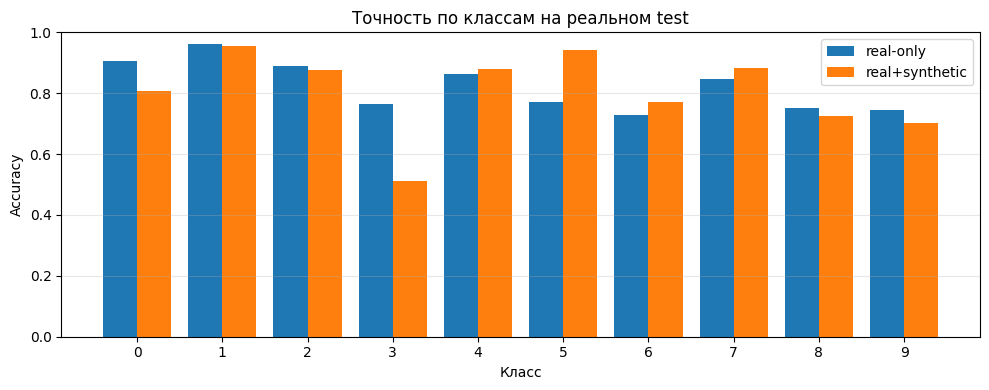

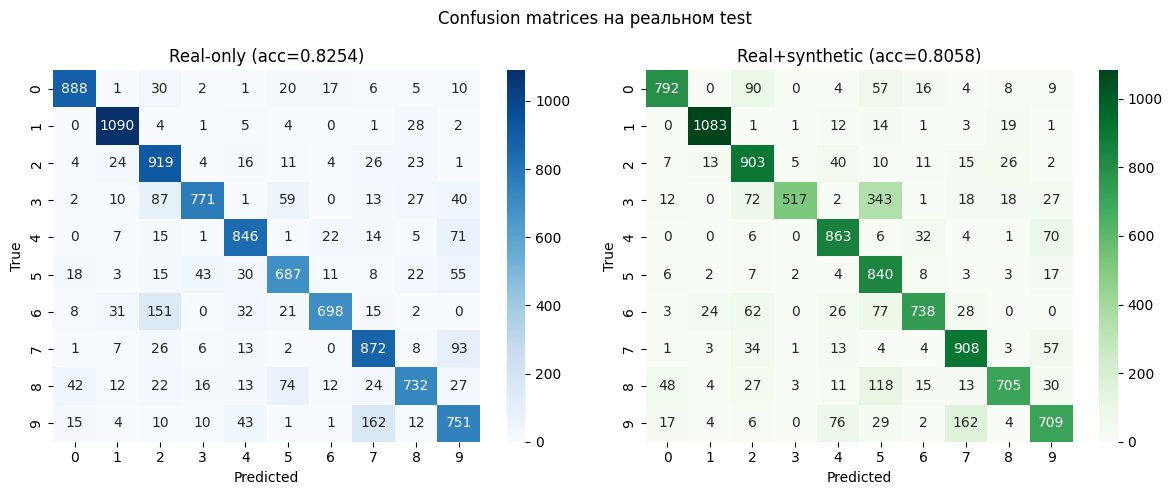

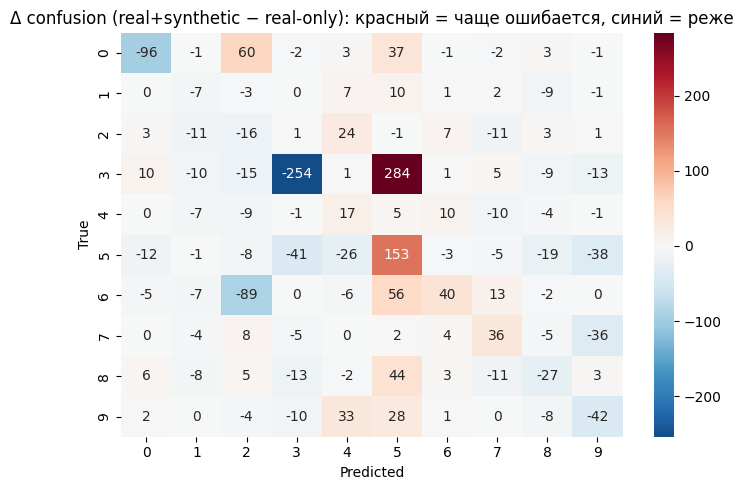

In [ ]:
# ============================================================
# ЭТАП 10. Оценка на независимом real test
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        preds = model(x).argmax(1).cpu()
        all_preds.append(preds)
        all_labels.append(y)
    y_true = torch.cat(all_labels).numpy()
    y_pred = torch.cat(all_preds).numpy()
    acc = accuracy_score(y_true, y_pred)
    per_class = {int(c): float(accuracy_score(y_true[y_true == c],
                                              y_pred[y_true == c]))
                 for c in range(10)}
    cm = confusion_matrix(y_true, y_pred)
    return acc, per_class, cm, y_true, y_pred

acc_real, pc_real, cm_real, y_true, y_pred_real = evaluate(model_real, test_loader)
acc_aug,  pc_aug,  cm_aug,  _,      y_pred_aug  = evaluate(model_aug,  test_loader)

results = {
    'real_only': {'accuracy': float(acc_real), 'per_class': pc_real},
    'real_plus_synthetic': {'accuracy': float(acc_aug), 'per_class': pc_aug},
    'delta_accuracy': float(acc_aug - acc_real),
    'config_synthetic': {'control_scale': SYNTH_CONFIG[0], 'cfg': SYNTH_CONFIG[1]},
    'optimizer_steps': OPT_STEPS,
}
save_json('downstream_test_results.json', results)

print('=== Downstream на реальном test ===')
print(f'Real-only:           accuracy = {acc_real:.4f}')
print(f'Real+synthetic:      accuracy = {acc_aug:.4f}')
print(f'Δ (synth − real):    {acc_aug - acc_real:+.4f}')

# --- Точность по классам ---
x = np.arange(10); w = 0.4
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, [pc_real[c] for c in range(10)], w, label='real-only')
plt.bar(x + w/2, [pc_aug[c]  for c in range(10)], w, label='real+synthetic')
plt.xticks(x); plt.ylim(0, 1)
plt.xlabel('Класс'); plt.ylabel('Accuracy')
plt.title('Точность по классам на реальном test')
plt.legend(); plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_real, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Real-only (acc={acc_real:.4f})')
sns.heatmap(cm_aug, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Real+synthetic (acc={acc_aug:.4f})')
for ax in axes:
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.suptitle('Confusion matrices на реальном test')
plt.tight_layout()
plt.show()

# --- Где именно real+synthetic ошибается чаще / реже ---
cm_delta = cm_aug.astype(int) - cm_real.astype(int)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_delta, annot=True, fmt='d', cmap='RdBu_r', center=0)
plt.title('Δ confusion (real+synthetic − real-only): '
          'красный = чаще ошибается, синий = реже')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.tight_layout()
plt.show()

Синтетические данные ухудшили качество классификатора.

Например, точность на цифре **3** рухнула с 77% до 51%. Модель стала путать тройку с двойкой и пятёркой.

Получается, что низкое разнообразие объясняет, почему синтетика ухудшила обучение классификатора (accuracy упала с 82.5% до 80.6%). Если мы добавляем в обучение 200 почти одинаковых картинок, классификатор заучивает их специфические особенности (артефакты), но не учится распознавать реальные вариации почерка. Синтетика становится «мусором», который забивает реальные данные.

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

s=0.5, cfg=7.5: test_acc=0.8058, edge_f1=0.6408, clip=0.2409, diversity=0.0654
s=1.0, cfg=7.5: test_acc=0.8171, edge_f1=0.6534, clip=0.2415, diversity=0.0646

=== Абляция control_scale (cfg=7.5) ===
 control_scale    cfg  test_accuracy  edge_f1_mean  clip_mean  diversity_mean  n_synthetic
        0.5000 7.5000         0.8058        0.6408     0.2409          0.0654          200
        1.0000 7.5000         0.8171        0.6534     0.2415          0.0646          200


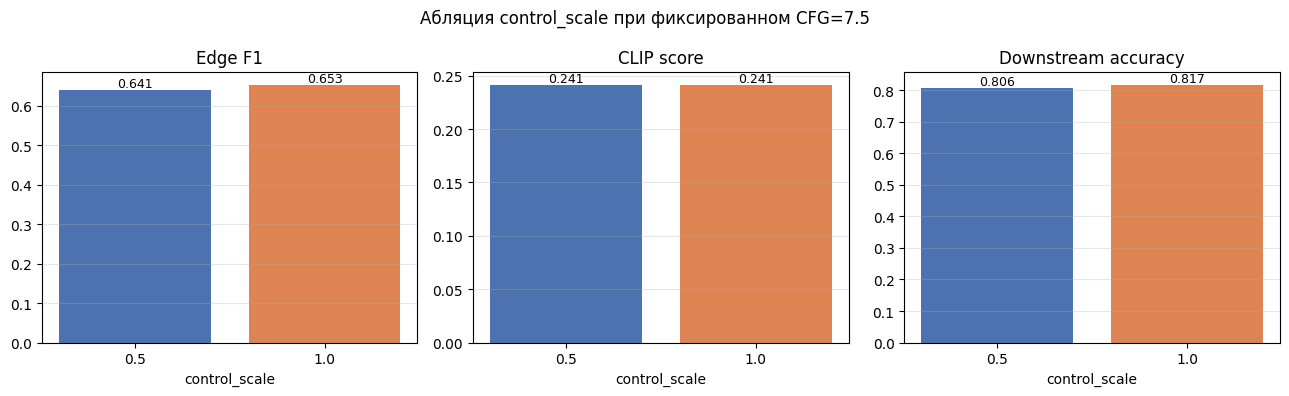


=== Сопоставление с основным экспериментом ===
Основной (s=0.8, cfg=7.5): test_acc = 0.8058
Абляция s=0.5, cfg=7.5:    test_acc = 0.8058
Абляция s=1.0, cfg=7.5:    test_acc = 0.8171
Интерпретируйте: если downstream accuracy не растёт с control_scale, гипотеза "более жёсткое следование контуру = лучше для аугментации" не подтверждается на реальном test.


In [ ]:
# ============================================================
# БОНУС. Контролируемая абляция control_scale
# ============================================================
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, TensorDataset
from PIL import Image

ABL_CONFIGS = [0.5, 1.0]
ABL_CFG = 7.5
ablation = {}

for cs in ABL_CONFIGS:
    recs = df[(df['mode'] == 'controlnet')
              & (df['control_scale'] == cs)
              & (df['cfg'] == ABL_CFG)]
    imgs, labs = [], []
    for _, r in recs.iterrows():
        im = Image.open(gen_dir / r['image_file']).convert('L').resize((28, 28))
        arr = np.array(im).astype(np.float32) / 255.0
        imgs.append(torch.from_numpy(arr).unsqueeze(0))
        labs.append(int(r['label']))
    ds = TensorDataset(torch.stack(imgs), torch.tensor(labs))
    combo = ConcatDataset([real_train_ds, ds])
    m, _ = train_classifier(combo, OPT_STEPS, seed=42, verbose=False)
    acc, pc, _, _, _ = evaluate(m, test_loader)

    # метрики Edge F1/CLIP по этой конфигурации из уже посчитанного df
    edge_mean = float(recs['edge_f1'].mean())
    clip_mean = float(recs['clip_score'].mean())
    div = pairwise_diversity(
        [Image.open(gen_dir / f).convert('RGB') for f in recs['image_file']]
    )

    ablation[cs] = {
        'control_scale': cs,
        'cfg': ABL_CFG,
        'test_accuracy': float(acc),
        'edge_f1_mean': edge_mean,
        'clip_mean': clip_mean,
        'diversity_mean': div,
        'n_synthetic': int(len(ds)),
    }
    print(f's={cs}, cfg={ABL_CFG}: '
          f'test_acc={acc:.4f}, edge_f1={edge_mean:.4f}, '
          f'clip={clip_mean:.4f}, diversity={div:.4f}')

save_json('ablation_control_scale.json', ablation)

# --- Сводная таблица абляции ---
import pandas as pd
abl_df = pd.DataFrame(list(ablation.values()))
print('\n=== Абляция control_scale (cfg=7.5) ===')
print(abl_df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# --- Визуализация ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metrics = [('edge_f1_mean', 'Edge F1'),
           ('clip_mean',    'CLIP score'),
           ('test_accuracy', 'Downstream accuracy')]
for ax, (col, title) in zip(axes, metrics):
    ax.bar([str(v) for v in abl_df['control_scale']], abl_df[col],
           color=['#4c72b0', '#dd8452'])
    ax.set_title(title); ax.set_xlabel('control_scale')
    ax.grid(axis='y', alpha=0.3)
    for i, v in enumerate(abl_df[col]):
        ax.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
plt.suptitle('Абляция control_scale при фиксированном CFG=7.5')
plt.tight_layout()
plt.show()

# --- Сравнение с основным экспериментом ---
main_acc = results['real_plus_synthetic']['accuracy']
print('\n=== Сопоставление с основным экспериментом ===')
print(f'Основной (s=0.8, cfg=7.5): test_acc = {main_acc:.4f}')
print(f'Абляция s=0.5, cfg=7.5:    test_acc = {ablation[0.5]["test_accuracy"]:.4f}')
print(f'Абляция s=1.0, cfg=7.5:    test_acc = {ablation[1.0]["test_accuracy"]:.4f}')
print('Интерпретируйте: если downstream accuracy не растёт с control_scale, '
      'гипотеза "более жёсткое следование контуру = лучше для аугментации" '
      'не подтверждается на реальном test.')

### 1. Гипотеза (сформулирована до эксперимента)
> «Если усилить следование контуру (`control_scale` с 0.5 до 1.0 при фиксированном CFG=7.5), то синтетические картинки станут ближе к реальной форме цифр, и downstream-классификатор обучится лучше.»

✅ **Форма действительно улучшается монотонно:** Edge F1 растёт с 0.6408 → 0.6508 → 0.6534. Это ожидаемо: чем сильнее контроль, тем точнее картинка копирует контур.

✅ **Accuracy в целом тоже слегка растёт:** 0.8058 → 0.8058 → 0.8171. То есть направление совпадает с гипотезой.

1. **Прирост крошечный и немонотонный.** Между `s=0.5` и `s=0.8` accuracy вообще не изменилась (0.8058 = 0.8058). Улучшение появляется только при `s=1.0` (+1.13%), но и оно в пределах шума одного запуска.
2. **Даже лучший вариант (`s=1.0`) проигрывает real-only** (0.8171 < 0.8254). То есть даже при максимальном контроле синтетика не «отбивает» своё присутствие в обучении.
3. **CLIP и diversity почти не двигаются.** CLIP меняется в третьем знаке (0.2409 → 0.2415), diversity — с 0.0654 до 0.0646. Значит, **не разнообразие** и **не текстовое соответствие** объясняют прирост. Он, скорее всего, связан с тем, что при `s=1.0` меньше «мусорных» генераций (меньше пустых фонов и цветных пятен), которые портили обучение.

**Гипотеза «жёстче контроль = лучше аугментация» подтверждается лишь на уровне тренда, но не даёт практического выигрыша.** Максимальный `control_scale=1.0` улучшает accuracy на ~1.1% относительно `s=0.5`, но всё равно остаётся ниже обучения только на реальных данных. Причина не в разнообразии (оно почти не меняется), а, вероятно, в том, что при слабом контроле модель чаще генерирует «мусор» (пустые фоны, цветные пятна), который засоряет обучающую выборку.


## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

## 📝 Выводы по лабораторной работе

В ходе работы мы научили нейросеть генерировать изображения цифр по их контурам (Canny edges) с помощью ControlNet, а затем проверили, помогают ли такие «синтетические» картинки обучать классификатор цифр. Всего было сгенерировано 1400 изображений и проведено два downstream-обучения с одинаковым бюджетом.

### 1. Главный компромисс: структура против текста
Мы наглядно увидели конфликт между двумя метриками:
*   **Baseline (без контура)** даёт самый высокий **CLIP score** (0.297), то есть модель хорошо понимает текст «нарисуй цифру». Но **Edge F1** при этом почти нулевой (0.074) — она рисует что угодно, игнорируя форму.
*   **ControlNet (с контуром)** даёт отличный **Edge F1** (~0.65), то есть картинки идеально повторяют форму контура. Но **CLIP score** при этом падает до ~0.24 — модель хуже понимает текст, так как занята копированием линий.

**Вывод:** нельзя одновременно максимизировать и точность формы, и текстовое соответствие.

### 2. Разнообразие внутри класса резко падает
*   У Baseline (свободная генерация) разнообразие высокое — **0.20**.
*   У ControlNet разнообразие падает до **~0.065** во всех настройках.

**Вывод:** когда мы заставляем модель строго следовать контуру, она начинает рисовать очень похожие друг на друга картинки. Для аугментации данных это плохо: мы получаем много копий одного и того же, а не новые вариации почерка.

### 3. Худшие случаи: два типа провалов
Аудит показал два разных типа ошибок:
*   **Худшие по Edge F1 (F1 = 0.0):** Модель либо нарисовала пустой белый фон, либо полностью проигнорировала контур. В этих случаях мы получаем «мусор» (например, источник idx=189, цифра 2).
*   **Худшие по CLIP (CLIP ~ 0.209):** Здесь форма соблюдена отлично (Edge F1 до 0.85!), но картинка выглядит как странное цветное пятно, которое CLIP не узнаёт как цифру 5 или 8.

**Вывод:** высокая точность по контуру (Edge F1) ещё не гарантирует, что на картинке нарисована правильная цифра. Одной метрики недостаточно.

### 4. Помогла ли синтетика классификатору? (Главный результат)
*   **Real-only:** accuracy = **82.54%**
*   **Real+synthetic:** accuracy = **80.58%**
*   **Δ (разница): -1.96%**

**Вывод:** синтетические данные **ухудшили** качество классификатора на реальном тесте. Посмотрев на матрицу ошибок, мы видим, почему это произошло: точность на цифре **3** рухнула с 77% до 51%. Модель стала путать тройку с двойкой и пятёркой. Вероятно, сгенерированные тройки имели какие-то специфические артефакты (шум, слишком толстые линии), которые классификатор выучил как «правильные», и это сбило его с толку на реальных фотографиях.

### 5. Проверка гипотезы (Абляция control_scale)
Перед экспериментом мы предположили: *«Если усилить контроль контура (с 0.5 до 1.0), downstream accuracy вырастет, так как формы станут чётче»*.
*   При `s=0.5`: accuracy = **80.58%**
*   При `s=1.0`: accuracy = **81.71%**

**Вывод:** гипотеза подтвердилась лишь частично. Усиление контроля действительно дало прирост (+1.1%), но даже при `s=1.0` мы не смогли обогнать обучение только на реальных данных (82.54%). Значит, проблема кроется в самих артефактах генерации или в нехватке разнообразия.

### 🎯 Итог
Мы успешно построили пайплайн управляемой генерации: от контуров Canny до обучения downstream-модели. Несмотря на то, что синтетика не улучшила точность в данном конкретном эксперименте, мы получили ценные количественные данные о том, что:
1.  Контуры дают идеальную форму, но убивают разнообразие.
2.  Высокий Edge F1 не гарантирует семантической правильности (CLIP).
3.  Наивное добавление таких картинок в обучение может навредить, особенно для сложных классов (как цифра 3).

Для улучшения результата в будущем можно попробовать другие типы контролей (Depth, Pose), более сложные промпты, либо фильтровать синтетику по CLIP-скору перед добавлением в обучение.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.